<h1>Tutorial of layer visualization for multi-label case</h1>

This notebook is provided to show the usage of UMAP for multiple label case. Please see another notebook <b>‘Tutorial of layer visualization’</b> as the first step.

NOTE: The script used 3rd module <a href=https://github.com/lmcinnes/umap>UMAP</a> for layer plotting.

<h2>1. Preparation</h2>

In this notebook, few packages are necessary. 

Assuming that we are in <b>'root-of-autoBioSeqpy/notebook'</b>, then we need to add the search path and import the modules.

Please install <b>UMAP, matplotlib, tensorFlow and keras</b> before using this notebook.

In [1]:
import os, sys
sys.path.append('../tool/libs')
sys.path.append('../')
oriPath = os.path.curdir
import paraParser
import moduleRead
import dataProcess
#import analysisPlot
import numpy as np
#from sklearn.metrics import accuracy_score,f1_score,roc_auc_score,recall_score,precision_score,confusion_matrix,matthews_corrcoef 
import tensorflow as tf
# import tensorflow.compat.v1 as tf
# tf.disable_v2_behavior() 
from utils import TextDecorate, evalStrList
# from keras.models import Model
# from keras.models import Sequential

# import umap
# import umap.plot
# import matplotlib.pyplot as plt
# from matplotlib.backends.backend_pdf import PdfPages

Using TensorFlow backend.
C:\Users\86182\anaconda3\lib\site-packages\tensorflow\python\framework\dtypes.py:516: FutureWarning: Passing (type, 1) or '1type' as a synonym of type is deprecated; in a future version of numpy, it will be understood as (type, (1,)) / '(1,)type'.
  _np_qint8 = np.dtype([("qint8", np.int8, 1)])
C:\Users\86182\anaconda3\lib\site-packages\tensorflow\python\framework\dtypes.py:517: FutureWarning: Passing (type, 1) or '1type' as a synonym of type is deprecated; in a future version of numpy, it will be understood as (type, (1,)) / '(1,)type'.
  _np_quint8 = np.dtype([("quint8", np.uint8, 1)])
C:\Users\86182\anaconda3\lib\site-packages\tensorflow\python\framework\dtypes.py:518: FutureWarning: Passing (type, 1) or '1type' as a synonym of type is deprecated; in a future version of numpy, it will be understood as (type, (1,)) / '(1,)type'.
  _np_qint16 = np.dtype([("qint16", np.int16, 1)])
C:\Users\86182\anaconda3\lib\site-packages\tensorflow\python\framework\dtypes.py

In [2]:
import viz_sequence

Using <a href=https://github.com/lmcinnes/umap>UMAP</a> is a simple way for model visualization, but still we need the model as well as the data for generating the predicted data for plotting. Thus, here we need few steps to get a built model and the related data.

<h3>1.1 Model building</h3>

Like the binary case, using running.py  could build a model:

<b>python running.py --dataType dna --dataEncodingType onehot --dataTrainFilePaths examples/CRISPRCas9guideefficiency/data/Doench_high_activity_sgRNA.txt examples/CRISPRCas9guideefficiency/data/Doench_low_activity_sgRNA.txt --dataTrainLabel 1 0 --dataSplitScale 0.8 --modelLoadFile examples/CRISPRCas9guideefficiency/model/DNA_CNN2D_model.py --verbose 1 --outSaveFolderPath tmpOut --savePrediction 1 --saveFig 1 --batch_size 25 --epochs 40 --shuffleDataTrain 1 --spcLen 30 --firstKernelSize 4 5 --modelSaveName tmpMod.json --weightSaveName tmpWeight.bin --noGPU 0 --paraSaveName parameters.txt
</b>

The outputs will be saved at <b>../tmpOut</b>, including the parameters, the path of the data and constructure of the model.

If users would like to use their own model, please don't forget to save the model and the weight by using parameters "--modelSaveName" and "--weightSaveName".

python running.py --dataType protein --dataEncodingType dict --dataTrainFilePaths examples/typeIII_secreted_effectors_prediction/data/train_pos.txt examples/typeIII_secreted_effectors_prediction/data/train_neg.txt --dataTrainLabel 1 0 --dataTestFilePaths examples/typeIII_secreted_effectors_prediction/data/test_pos.txt examples/typeIII_secreted_effectors_prediction/data/test_neg.txt --dataTestLabel 1 0 --modelLoadFile examples/typeIII_secreted_effectors_prediction/model/protein_CNN_model.py --verbose 1 --outSaveFolderPath tmpOut --savePrediction 1 --saveFig 1 --batch_size 60 --epochs 20 --spcLen 100 --shuffleDataTrain 1 --modelSaveName tmpMod.json --weightSaveName tmpWeight.bin --noGPU 0 --paraSaveName parameters.txt

<h3>1.2 Parameter pasering and data loading</h3>
The parameters are saved in <b>../tmoOut/parameters.txt</b>, we can get the information easily by using the <b>paraParser</b> module.

In [3]:
paraFile = '../tmpOut/parameters.txt'
paraDict = paraParser.parseParametersFromFile(paraFile)
#print
for k in paraDict:
    print('%r: %r' %(k,paraDict[k]))

'dataType': ['dna']
'dataEncodingType': ['onehot']
'spcLen': [101]
'firstKernelSize': []
'dataTrainFilePaths': ['examples/TF/data/train/positive.txt', 'examples/TF/data/train/negative.txt']
'dataTrainLabel': [1, 0]
'dataTestFilePaths': []
'dataTestLabel': []
'dataTrainModelInd': []
'dataTestModelInd': []
'outSaveFolderPath': 'tmpOut'
'showFig': True
'saveFig': True
'figDPI': 300
'savePrediction': True
'dataSplitScale': 0.9
'modelLoadFile': ['examples/TF/model/CNN-RNN.py']
'weightLoadFile': []
'shuffleDataTrain': True
'shuffleDataTest': False
'batch_size': 50
'epochs': 40
'useKMer': []
'KMerNum': []
'inputLength': []
'loss': 'binary_crossentropy'
'optimizer': 'optimizers.Adam()'
'metrics': ['acc', 'acc']
'modelSaveName': 'tmpMod.json'
'weightSaveName': 'tmpWeight.bin'
'noGPU': False
'paraFile': None
'paraSaveName': 'parameters.txt'
'seed': 1
'labelToMat': False
'colorText': 'Auto'
'verbose': True
'reshapeSize': []


Then using <b>predicting</b> module could help us get the model and the datasets.

In [4]:
import predicting

Here we need some modification to specify the dataset due to the layer plotting needs the training dataset.

In [5]:
paraDict['dataTestFilePaths'] = paraDict['dataTrainFilePaths']
paraDict['dataTestModelInd'] = paraDict['dataTrainModelInd']
paraDict['dataTestLabel'] = paraDict['dataTrainLabel']

In [6]:
os.chdir('../')#to the root path of autoBioSeqpy

In [7]:
predictedLabel,predicted_Probability,testNameLists,testDataMats,testLabelArr,model = predicting.predict(paraDict)    




Enconding DNA data for model 0 ...
Checking the number of test files, which should be larger than 1 (e.g. at least two labels)...
Begin to generate test dataset...
Test datasets generated.
begin to prepare model...
Checking module file for modeling
Loading module and weight file
Building model...

Module loaded, generating the summary of the module
Model: "sequential_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
reshape_1 (Reshape)          (None, 101, 4)            0         
_________________________________________________________________
conv1d_1 (Conv1D)            (None, 99, 250)           3250      
_________________________________________________________________
max_pooling1d_1 (MaxPooling1 (None, 49, 250)           0         
_________________________________________________________________
bidirectional_1 (Bidirection (None, 128)               161280    
______________________________

Please note that the test label will NOT used for predicting, thus we have to generate it manually.

In [8]:
featureGenerators = []
dataTypeList = paraDict['dataType']
verbose = False
dataEncodingType = paraDict['dataEncodingType']
KMerNumList = useKMerList = [False] * 400
dataTestFilePaths = paraDict['dataTestFilePaths']
modelLoadFile = paraDict['modelLoadFile']
dataTestModelInd = paraDict['dataTestModelInd']
dataTestModelInd = [0] * len(dataTestFilePaths)
spcLen = paraDict['spcLen']
for i,subDataType in enumerate(dataTypeList):
    if subDataType.lower() == 'protein':
        if verbose:
            td.printC('Enconding protein data for model %d ...' %i,'b')
        featureGenerator = dataProcess.ProteinFeatureGenerator(dataEncodingType[i], useKMer=useKMerList[i], KMerNum=KMerNumList[i])
    elif subDataType.lower() == 'dna':
        if verbose:
            td.printC('Enconding DNA data for model %d ...' %i,'b')
        featureGenerator = dataProcess.DNAFeatureGenerator(dataEncodingType[i], useKMer=useKMerList[i], KMerNum=KMerNumList[i])
    elif subDataType.lower() == 'rna':
        if verbose:
            td.printC('Enconding RNA data for model %d ...' %i,'b')
        featureGenerator = dataProcess.RNAFeatureGenerator(dataEncodingType[i], useKMer=useKMerList[i], KMerNum=KMerNumList[i])
    elif subDataType.lower() == 'other':
        if verbose:
            td.printC('Reading CSV-like data for model %d ...' %i,'b')
        featureGenerator = dataProcess.OtherFeatureGenerator()
    else:
        td.printC('Unknow dataType %r, please use \'protein\', \'dna\' ,\'rna\' or \'other\'' %subDataType, 'r')
    featureGenerators.append(featureGenerator)
    assert subDataType.lower() in ['protein','dna','rna','other']

if verbose:
    td.printC('Checking the number of test files, which should be larger than 1 (e.g. at least two labels)...','b')
assert len(dataTestFilePaths) > 0

if verbose:
    td.printC('Begin to generate test dataset...','b')

testDataLoadDict = {}    
for modelIndex in range(len(modelLoadFile)):
    testDataLoadDict[modelIndex] = []
#    testDataLoaders = []
for i,dataPath in enumerate(dataTestFilePaths):
    modelIndex = dataTestModelInd[i]
    featureGenerator = featureGenerators[modelIndex]
    dataLoader = dataProcess.DataLoader(label = paraDict['dataTestLabel'][i], featureGenerator=featureGenerator)
    dataLoader.readFile(dataPath, spcLen = spcLen[modelIndex])
    testDataLoadDict[modelIndex].append(dataLoader)

testDataMats = []
testLabelArrs = []
testNameLists = []
for modelIndex in range(len(modelLoadFile)):
    testDataLoaders = testDataLoadDict[modelIndex]
    testDataSetCreator = dataProcess.DataSetCreator(testDataLoaders)
    testDataMat, testLabelArr, nameList = testDataSetCreator.getDataSet(toShuffle=False, withNameList=True)
    testDataMats.append(testDataMat)
    testLabelArrs.append(testLabelArr)
    testNameLists.append(nameList)
if verbose:
    td.printC('Test datasets generated.','g')
nameTemp = testNameLists[0]    
testDataMats, testLabelArrs, sortedIndexes = dataProcess.matAlignByName(testDataMats,nameTemp,testLabelArrs,testNameLists)
testNameLists = [nameTemp] * len(testNameLists)

tmpTempLabel = testLabelArrs[0]

Few printing operations for display the current information.

In [9]:
testLabelArr.shape

(1923,)

In [10]:
print('%d matrix generated:\n' %(len(testDataMats)))
for i in range(len(testDataMats)):
    print('Matrix and label %d:' %i)
    print(testDataMats[i])
    print(testLabelArrs[i])
    print('\n')

1 matrix generated:

Matrix and label 0:
[[0 0 1 ... 1 0 0]
 [0 0 1 ... 1 0 0]
 [0 0 1 ... 0 0 1]
 ...
 [0 0 1 ... 0 0 0]
 [0 0 1 ... 0 0 1]
 [1 0 0 ... 0 0 1]]
[1 1 1 ... 0 0 0]




In [11]:
import matplotlib.pyplot as plt

In [12]:
import shap

In [13]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
reshape_1 (Reshape)          (None, 101, 4)            0         
_________________________________________________________________
conv1d_1 (Conv1D)            (None, 99, 250)           3250      
_________________________________________________________________
max_pooling1d_1 (MaxPooling1 (None, 49, 250)           0         
_________________________________________________________________
bidirectional_1 (Bidirection (None, 128)               161280    
_________________________________________________________________
dropout_1 (Dropout)          (None, 128)               0         
_________________________________________________________________
activation_1 (Activation)    (None, 128)               0         
_________________________________________________________________
dense_1 (Dense)              (None, 1)                

In [14]:
from keras import backend as K
session = K.get_session()

In [15]:
explainer = shap.GradientExplainer(model, testDataMats[0][:,:],session=session)

In [16]:
shap_values = explainer.shap_values(testDataMats[0][:,:])

In [17]:
shap_values

[array([[-3.02561850e-04, -7.64749362e-04,  1.07438955e-03, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [-1.23510789e-03, -1.45360606e-03, -4.26406786e-03, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [-4.32645727e-04, -1.78953516e-04, -1.07575872e-03, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        ...,
        [-7.13638903e-04, -3.78620927e-04, -1.07958436e-03, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [-4.06578270e-04,  1.62654251e-05, -8.36508174e-04, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 7.62969081e-04, -6.61112281e-05,  8.91803866e-05, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00]])]

In [18]:
shap_values[0].shape


(1923, 404)

In [19]:
testDataMats[0].shape

(1923, 404)

In [20]:
testDataLoadDict[0][1].names

['negative.txt_CHR1:157893034-157893135',
 'negative.txt_CHR1:236458435-236458536',
 'negative.txt_CHR1:49030257-49030358',
 'negative.txt_CHR1:158179164-158179265',
 'negative.txt_CHR1:238421811-238421912',
 'negative.txt_CHR1:33593308-33593409',
 'negative.txt_CHR1:159352339-159352440',
 'negative.txt_CHR1:113841057-113841158',
 'negative.txt_CHR1:207524961-207525062',
 'negative.txt_CHR1:151149531-151149632',
 'negative.txt_CHR1:97573618-97573719',
 'negative.txt_CHR1:170334133-170334234',
 'negative.txt_CHR1:156575772-156575873',
 'negative.txt_CHR1:54031444-54031545',
 'negative.txt_CHR1:210299879-210299980',
 'negative.txt_CHR1:9067617-9067718',
 'negative.txt_CHR1:23082735-23082836',
 'negative.txt_CHR1:152498225-152498326',
 'negative.txt_CHR1:185597371-185597472',
 'negative.txt_CHR1:67955660-67955761',
 'negative.txt_CHR1:85234746-85234847',
 'negative.txt_CHR1:80836767-80836868',
 'negative.txt_CHR1:221769029-221769130',
 'negative.txt_CHR1:192831632-192831733',
 'negative.t

In [21]:
print(len(testDataLoadDict[0][0].names))
print(len(testDataLoadDict[0][1].names))

1000
923


In [22]:
dataLoaders = testDataLoadDict[0]

In [23]:
class seqWithShaps:
    def __init__(self,seqStr,shapVals,plotFea=None):
        self.seqStr = seqStr
        self.shapVals = shapVals
        if not plotFea is None:
            self.plotFea = plotFea
        else:
            self.plotFea = {}
            self.plotFea['color'] = {'A':'green','T':'red','C':'blue','G':'orange'}
            self.plotFea['method'] = {'A':viz_sequence.plot_a,'T':viz_sequence.plot_t,'C':viz_sequence.plot_c,'G':viz_sequence.plot_g}
            self.plotFea['figSize'] = (16,12)
        if len(self.seqStr) > len(self.shapVals):
            print()
            
    def plot(self):
        seqStr = self.seqStr.upper()
        fig, ax = plt.subplots(figsize=self.plotFea['figSize'])
        for i,s in enumerate(seqStr):
            base = 0
            left_edge = i + 0.5
            height = self.shapVals[i]
            color = self.plotFea['color'][s]
            plotMethod = self.plotFea['method'][s]
            plotMethod(ax,base,left_edge,height,color)
        ax.set_xlim((0,len(self.shapVals)))
        ax.set_ylim((np.min(self.shapVals),np.max(self.shapVals)))
        plt.show()
    

In [25]:
tmpObj = seqWithShaps(dataLoaders[0].seqs[dataLoaders[0].names[0]],shap_values[0][0,:].reshape(101,4).sum(axis=1))

In [26]:
len(dataLoaders[0].seqs[dataLoaders[0].names[0]])

101

In [27]:
shap_values[0][0,:].shape

(404,)

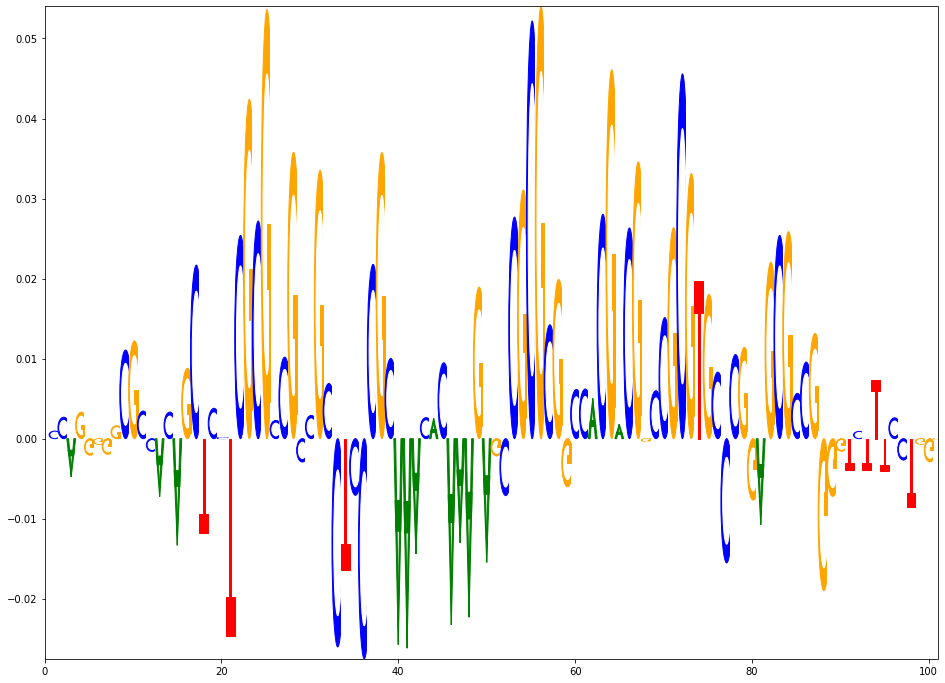

In [28]:
tmpObj.plot()

In [ ]:
class seqMatWithShaps:
    def __init__(self,plotFea=None):
        self.seqStrList = []
        self.posValDict = {}
        if not plotFea is None:
            self.plotFea = plotFea
        else:
            self.plotFea = {}
            self.plotFea['color'] = {'A':'red','T':'orange','C':'blue','G':'green'}
            self.plotFea['method'] = {'A':viz_sequence.plot_a,'T':viz_sequence.plot_t,'C':viz_sequence.plot_c,'G':viz_sequence.plot_g}
            self.plotFea['figSize'] = (16,9)
    
    def fillDict(self,seqStr,shapVals,valPreprocessMethod = None):
        for i,s in enumerate(seqStr):
            shapVal = shapVals[i]
            if not valPreprocessMethod is None:
                shapVal = valPreprocessMethod(shapVal)
            if not i in self.posValDict:
                self.posValDict[i] = {}
            if not s in self.posValDict[i]:
                self.posValDict[i][s] = shapVal
            else:
                self.posValDict[i][s] += shapVal
    
    def plot(self, valThres = None):
        fig, ax = plt.subplots(figsize=self.plotFea['figSize'])
        yLimMin = 1e10
        yLimMax = -1e10
        for i in self.posValDict:
            keyList = []
            valList = []
            for k in self.posValDict[i]:
                keyList.append(k)
                valList.append(self.posValDict[i][k])
            sortIndex = np.argsort(np.abs(valList))
#             print(np.array(valList)[sortIndex])
            baseNeg = 0
            basePos = 0
            for pos in sortIndex:
                s = keyList[pos]                
                left_edge = i + 0.5
                height = valList[pos]
                if np.abs(height) < valThres:
                    continue
                if not s in self.plotFea['color']:
                    continue
                color = self.plotFea['color'][s]
                plotMethod = self.plotFea['method'][s]
                if height >= 0:
                    base = basePos
                    basePos += height
                else:
                    base = baseNeg
                    baseNeg = baseNeg + height
                plotMethod(ax,base,left_edge,height,color)
                
                
            yLimMin = np.min((yLimMin,np.min(valList)))
            yLimMax = np.max((yLimMax,np.max(valList)))
        ax.set_xlim((0,len(self.posValDict.keys()) + 2 ))
        ax.set_ylim((yLimMin-1,yLimMax+1))
        plt.show()
        
    def plot_max(self, valThres = None):
        fig, ax = plt.subplots(figsize=self.plotFea['figSize'])
        yLimMin = 1e10
        yLimMax = -1e10
        for i in self.posValDict:
            keyList = []
            valList = []
            for k in self.posValDict[i]:
                keyList.append(k)
                valList.append(self.posValDict[i][k])
            sortIndex = np.argsort(np.abs(valList))
#             print(np.array(valList)[sortIndex])
            baseNeg = 0
            basePos = 0
            bestPos = None
            bestH = None
            for pos in sortIndex:
                s = keyList[pos]                
                left_edge = i + 0.5
                height = valList[pos]
                if bestH is None:
                    bestH = height
                    bestPos = pos
                else:
                    if np.abs(height) > np.abs(bestH):
                        bestH = height
                        bestPos = pos
            for pos in [bestPos]:
                s = keyList[pos]                
                left_edge = i + 0.5
                height = valList[pos]
                if np.abs(height) < valThres:
                    continue
                if not s in self.plotFea['color']:
                    continue
                color = self.plotFea['color'][s]
                plotMethod = self.plotFea['method'][s]
                if height >= 0:
                    base = basePos
                    basePos += height
                else:
                    base = baseNeg
                    baseNeg = baseNeg + height
                plotMethod(ax,base,left_edge,height,color)
                
                
            yLimMin = np.min((yLimMin,np.min(valList)))
            yLimMax = np.max((yLimMax,np.max(valList)))
        ax.set_xlim((0,len(self.posValDict.keys()) + 2 ))
        ax.set_ylim((yLimMin-1,yLimMax+1))
        plt.show()

In [ ]:
tmpObjPos = seqMatWithShaps()
tmpObjNeg = seqMatWithShaps()

In [ ]:
i = 0
for name in dataLoaders[0].names:
    seqStr = dataLoaders[0].seqs[name][48:51]
    tmpVals = shap_values[0][i,:][48:51]
    tmpObjPos.fillDict(seqStr,tmpVals)
    i += 1
for name in dataLoaders[1].names:
    seqStr = dataLoaders[1].seqs[name]
    tmpVals = shap_values[0][i,:]
    tmpObjNeg.fillDict(seqStr,tmpVals)
    i += 1

In [ ]:
tmpObjPos.plot(valThres=1)
tmpObjNeg.plot(valThres=1)

In [ ]:
tmpObjPos.plot_max(valThres=1)
tmpObjNeg.plot_max(valThres=1)

In [ ]:
tmpObjPos.plotFea['figSize'] = (64,9)
tmpObjPos.plot_max(valThres=0.6)